In [33]:
#Importar Librerias

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

In [34]:
import kagglehub

# descarga el dataset
path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")

print("Ruta del archivo:", path)

# cargar el CSV directamente
df = pd.read_csv(f"{path}/heart.csv")

print("Dimensiones:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all"))

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.
Ruta del archivo: /kaggle/input/heart-failure-prediction
Dimensiones: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


None

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918,918,918.000000,918.000000,918.000000,918,918.000000,918,918.000000,918,918.000000
unique,NaN,2,4,NaN,NaN,NaN,3,NaN,2,NaN,3,NaN
top,NaN,M,ASY,NaN,NaN,NaN,Normal,NaN,N,NaN,Flat,NaN
freq,NaN,725,496,NaN,NaN,NaN,552,NaN,547,NaN,460,NaN
mean,53.510893,NaN,NaN,132.396514,198.799564,0.233115,NaN,136.809368,NaN,0.887364,NaN,0.553377
std,9.432617,NaN,NaN,18.514154,109.384145,0.423046,NaN,25.460334,NaN,1.066570,NaN,0.497414
min,28.000000,NaN,NaN,0.000000,0.000000,0.000000,NaN,60.000000,NaN,-2.600000,NaN,0.000000
25%,47.000000,NaN,NaN,120.000000,173.250000,0.000000,NaN,120.000000,NaN,0.000000,NaN,0.000000
50%,54.000000,NaN,NaN,130.000000,223.000000,0.000000,NaN,138.000000,NaN,0.600000,NaN,1.000000
75%,60.000000,NaN,NaN,140.000000,267.000000,0.000000,NaN,156.000000,NaN,1.500000,NaN,1.000000


In [35]:
print("Valores nulos:")
display(df.isnull().sum())

print("Ceros en columnas relevantes:")
display((df[["Cholesterol", "RestingBP", "FastingBS"]] == 0).sum())

Valores nulos:


,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


Ceros en columnas relevantes:


,0
Cholesterol,172
RestingBP,1
FastingBS,704


Los ceros de Cholesterol y RestingBP representan valores no informados,
por lo que se convierten en NaN y se imputan dentro del pipeline.

El valor 0 de FastingBS sí es válido y representa que la glucemia en ayunas
no supera 120 mg/dl. Por eso no se reemplaza.

HeartDisease
1    508
0    410
Name: count, dtype: int64
HeartDisease
1    0.553377
0    0.446623
Name: proportion, dtype: float64


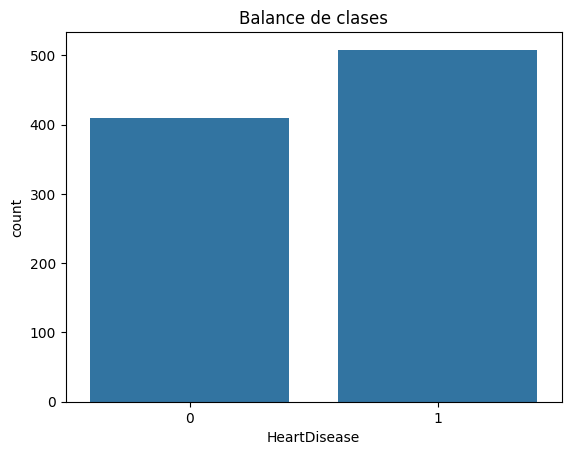

In [36]:
print(df["HeartDisease"].value_counts())
print(df["HeartDisease"].value_counts(normalize=True))

sns.countplot(data=df, x="HeartDisease")
plt.title("Balance de clases")
plt.show()

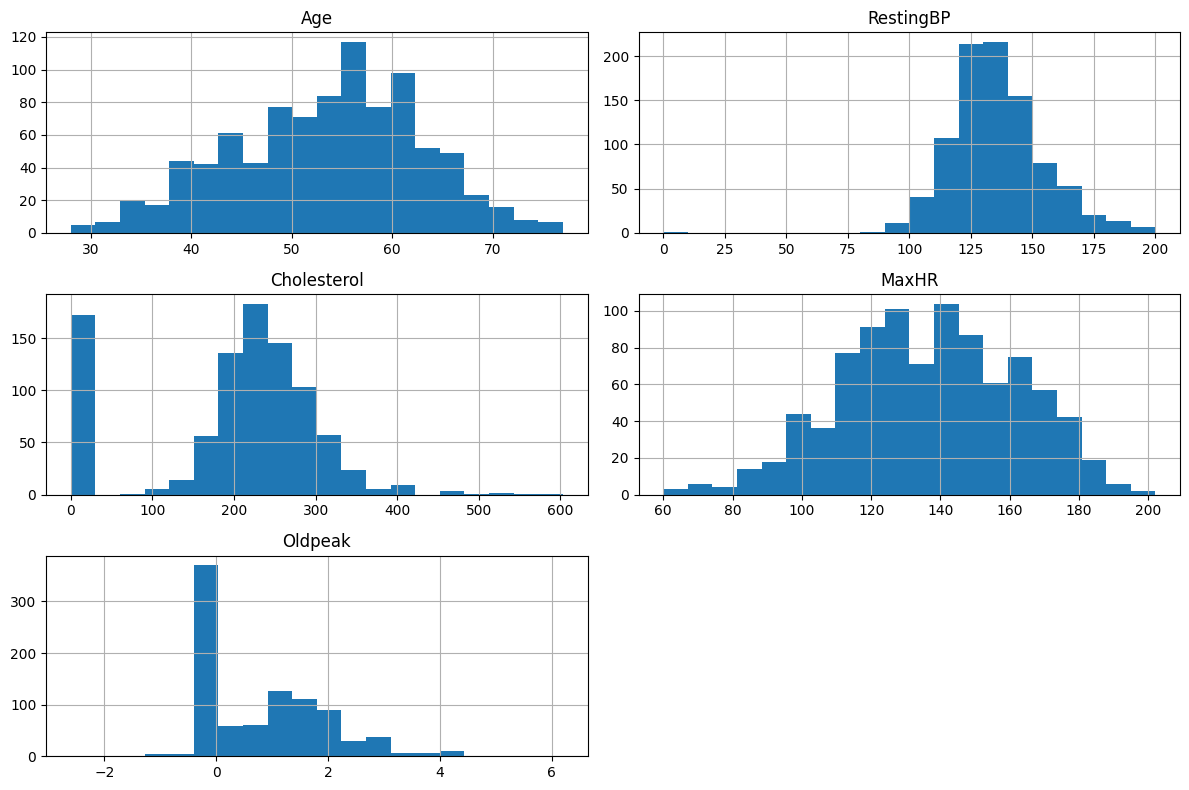

In [37]:
numeric_columns = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak"
]

df[numeric_columns].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

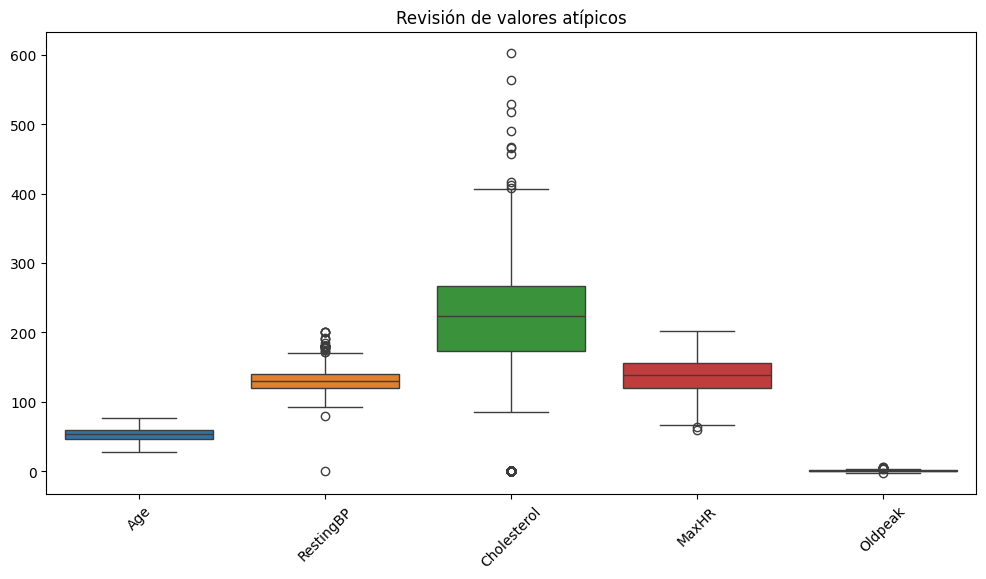

In [38]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_columns])
plt.xticks(rotation=45)
plt.title("Revisión de valores atípicos")
plt.show()

In [39]:
TARGET = "HeartDisease"

CATEGORICAL = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

NUMERIC = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak"
]

FEATURES = NUMERIC + CATEGORICAL

X = df[FEATURES].copy()
y = df[TARGET]

X[["Cholesterol", "RestingBP"]] = (
    X[["Cholesterol", "RestingBP"]].replace(0, np.nan)
)

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [41]:
preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        NUMERIC
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ))
        ]),
        CATEGORICAL
    )
])

In [42]:
majority_class = y_train.mode()[0]
baseline_predictions = np.full(len(y_test), majority_class)

print("Clase mayoritaria:", majority_class)
print("Accuracy baseline:",
      accuracy_score(y_test, baseline_predictions))
print("Macro-F1 baseline:",
      f1_score(
          y_test,
          baseline_predictions,
          average="macro"
      ))

Clase mayoritaria: 1
Accuracy baseline: 0.5543478260869565
Macro-F1 baseline: 0.35664335664335667


In [43]:
random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        )
    )
])

random_forest_pipeline.fit(X_train, y_train)
rf_predictions = random_forest_pipeline.predict(X_test)

print(classification_report(y_test, rf_predictions))
print("Matriz de confusión - Random Forest:")
print(confusion_matrix(y_test, rf_predictions))


              precision    recall  f1-score   support

           0       0.84      0.84      0.84        82
           1       0.87      0.87      0.87       102

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184

Matriz de confusión - Random Forest:
[[69 13]
 [13 89]]


In [44]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        XGBClassifier(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.05,
            random_state=42,
            eval_metric="logloss",
            n_jobs=1
        )
    )
])

xgb_pipeline.fit(X_train, y_train)
xgb_predictions = xgb_pipeline.predict(X_test)

print(classification_report(y_test, xgb_predictions))

print("Matriz de confusión - XGBoost:")
print(confusion_matrix(y_test, xgb_predictions))

              precision    recall  f1-score   support

           0       0.85      0.84      0.85        82
           1       0.87      0.88      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184

Matriz de confusión - XGBoost:
[[69 13]
 [12 90]]


In [45]:
comparison = pd.DataFrame([
    {
        "Modelo": "Baseline",
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "Macro-F1": f1_score(
            y_test,
            baseline_predictions,
            average="macro"
        )
    },
    {
        "Modelo": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Macro-F1": f1_score(
            y_test,
            rf_predictions,
            average="macro"
        )
    },
    {
        "Modelo": "XGBoost",
        "Accuracy": accuracy_score(y_test, xgb_predictions),
        "Macro-F1": f1_score(
            y_test,
            xgb_predictions,
            average="macro"
        )
    }
])

display(comparison)

,Modelo,Accuracy,Macro-F1
0,Baseline,0.554348,0.356643
1,Random Forest,0.858696,0.857006
2,XGBoost,0.864130,0.862337


Matriz de confusión:
[[69 13]
 [12 90]]
TN: 69
FP: 13
FN: 12
TP: 90


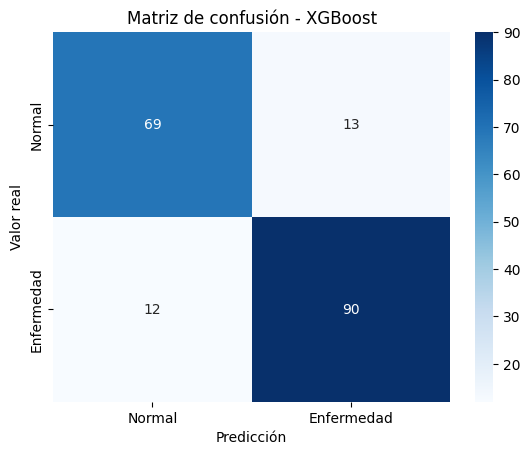

In [46]:
cm = confusion_matrix(y_test, xgb_predictions)

print("Matriz de confusión:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Enfermedad"],
    yticklabels=["Normal", "Enfermedad"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - XGBoost")
plt.show()

## Interpretación de resultados

La referencia de clase mayoritaria obtuvo un accuracy de 55,43 %.
Random Forest obtuvo 85,87 % y macro-F1 de 85,70 %.
XGBoost obtuvo 86,41 % y macro-F1 de 86,23 %.

La matriz de confusión de XGBoost fue:

- TN = 69
- FP = 13
- FN = 12
- TP = 90

Estos resultados corresponden a una única partición estratificada de 184
registros. Por lo tanto, la evaluación es exploratoria y no garantiza el
comportamiento del modelo sobre pacientes nuevos.

In [50]:
import joblib

joblib.dump(xgb_pipeline, "pipeline_xgboost_fase2.pkl")
print("Pipeline guardado correctamente")

Pipeline guardado correctamente


In [51]:
pipeline_cargado = joblib.load("pipeline_xgboost_fase2.pkl")

fila_prueba = X_test.iloc[[0]]

prediccion = pipeline_cargado.predict(fila_prueba)
probabilidad = pipeline_cargado.predict_proba(fila_prueba)

print("Predicción:", prediccion)
print("Probabilidad:", probabilidad)

Predicción: [1]
Probabilidad: [[0.05126601 0.948734  ]]


In [52]:
import subprocess
import sys

codigo = """
import joblib
import pandas as pd

pipeline = joblib.load("pipeline_xgboost_fase2.pkl")

fila = pd.DataFrame({
    "Age": [40],
    "Sex": ["M"],
    "ChestPainType": ["ATA"],
    "RestingBP": [140],
    "Cholesterol": [289],
    "FastingBS": [0],
    "RestingECG": ["Normal"],
    "MaxHR": [172],
    "ExerciseAngina": ["N"],
    "Oldpeak": [0.0],
    "ST_Slope": ["Up"]
})

print("Predicción:", pipeline.predict(fila))
print("Probabilidad:", pipeline.predict_proba(fila))
"""

resultado = subprocess.run(
    [sys.executable, "-c", codigo],
    capture_output=True,
    text=True,
    check=True
)

print(resultado.stdout)

Predicción: [0]
Probabilidad: [[0.963457   0.03654304]]



## Diferencias y correcciones frente a la Fase 1

| Aspecto | Fase 1 | Fase 2 | Consecuencia |
|---|---|---|---|
| Valores cero | Se conservaron `Cholesterol=0` y `RestingBP=0` | Se convierten en `NaN` y se imputan con la mediana | Cambian algunos valores de entrada y predicciones |
| Preprocesamiento | `pd.get_dummies` antes de dividir | `Pipeline` y `ColumnTransformer` ajustados con entrenamiento | Se evita fuga de informaci?n |
| Comparaci?n | Se reportó principalmente XGBoost | Se agrega baseline y Random Forest en la misma partición | La comparaci?n es más verificable |
| Persistencia | Se guardó solo el clasificador codificado | Se guarda el pipeline completo | Se puede predecir usando los 11 campos originales |


En la evaluación original de Fase 1 se reportaron 163 aciertos de 184 (88,6 %), con TN=72, FP=10, FN=11 y TP=91. En esta Fase 2, después de tratar los valores ausentes y ajustar el pipeline sin fuga, se obtuvieron 159 aciertos de 184 (86,4 %), con TN=69, FP=13, FN=12 y TP=90.


